# Лабораторная работа 2. Моделирование дискретных СВ.

## Условие задачи

**Вариант 10.**

Смоделировать дискретную случайную величину (задания на стр. 18–22). Исследовать точность моделирования.

1. Осуществить моделирование $n = 1000$ реализаций СВ из заданных дискретных распределений:
   - распределение **Пуассона** $\Pi(\lambda)$ с параметром $\lambda = 0.7$;
   - **геометрическое** распределение $G(p)$ с параметром $p = 0.2$.

2. Вывести на экран несмещённые оценки математического ожидания и дисперсии, сравнить их с истинными значениями.

3. Для каждой из случайных величин построить свой $\chi^2$-критерий Пирсона с уровнем значимости $\varepsilon = 0.05$. Проверить, что вероятность ошибки I рода стремится к $0.05$.

4. Осуществить проверку каждой из сгенерированных выборок каждым из построенных критериев.

## Параметры варианта

| Распределение | Обозначение | Параметр | Носитель |
|---------------|-------------|----------|----------|
| Пуассона | $\Pi(\lambda)$ | $\lambda = 0.7$ | $k = 0, 1, 2, \ldots$ |
| Геометрическое | $G(p)$ | $p = 0.2$ | $k = 1, 2, 3, \ldots$ |

Объём выборки: $n = 1000$. Уровень значимости: $\varepsilon = 0.05$.

# Теория

## Распределение Пуассона $\Pi(\lambda)$

Дискретная случайная величина $X$ имеет распределение Пуассона с параметром $\lambda > 0$, если её возможные значения $k = 0, 1, 2, \ldots$, а вероятности определяются формулой

$$
P(X = k) = \frac{\lambda^k}{k!} \, e^{-\lambda}, \qquad k = 0, 1, 2, \ldots
$$

Числовые характеристики:

$$
E[X] = \lambda, \qquad D[X] = \lambda.
$$

В данной работе для **первой СВ** бралось значение:

$$
\lambda = 0.7.
$$

Тогда $E[X] = 0.7$ и $D[X] = 0.7$.

## Геометрическое распределение $G(p)$

Дискретная случайная величина $X$ имеет геометрическое распределение с параметром $p \in (0, 1]$, если она описывает **число испытаний до первого успеха** (включая успешное), $k = 1, 2, 3, \ldots$, а вероятности равны

$$
P(X = k) = (1 - p)^{k-1} \, p, \qquad k = 1, 2, 3, \ldots
$$

Числовые характеристики:

$$
E[X] = \frac{1}{p}, \qquad D[X] = \frac{1 - p}{p^2}.
$$

В данной работе для **второй СВ** бралось значение:

$$
p = 0.2.
$$

Тогда $E[X] = 5$ и $D[X] = \dfrac{0.8}{0.04} = 20$.

> **Замечание о конвенции.** Используется конвенция «число испытаний до первого успеха» ($k = 1, 2, \ldots$). Альтернативная конвенция — «число неудач до первого успеха» ($k = 0, 1, \ldots$) — даёт $E[X] = (1-p)/p$, $D[X] = (1-p)/p^2$. В работе используется первая.

## Метод обратного преобразования

Для моделирования дискретной СВ с известной функцией распределения $F(x) = P(X \le x)$ используется **метод обратного преобразования**:

1. Генерируется реализация $u$ равномерной БСВ на $[0, 1]$.
2. Ищется минимальное $k$, для которого выполняется $F(k) = P(X \le k) \ge u$.
3. Это $k$ и есть реализация $X$.

Метод универсален и работает для любого дискретного распределения, у которого можно вычислить CDF.

**Для Пуассона** вероятности считаются рекуррентно:

$$
p_0 = e^{-\lambda}, \qquad p_k = p_{k-1} \cdot \frac{\lambda}{k}.
$$

Накопление $F(k) = \sum_{j=0}^{k} p_j$ продолжается, пока $F(k) < u$.

**Для геометрического** CDF имеет замкнутую форму:

$$
F(k) = P(X \le k) = 1 - (1 - p)^k, \qquad k = 1, 2, \ldots
$$

Из условия $1 - (1-p)^k \ge u$ получаем

$$
k = \left\lceil \frac{\ln(1 - u)}{\ln(1 - p)} \right\rceil.
$$

## Несмещённые оценки математического ожидания и дисперсии

По выборке $x_1, \ldots, x_n$:

$$
\hat{E}[X] = \bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i,
\qquad
\hat{D}[X] = s^2 = \frac{1}{n - 1} \sum_{i=1}^{n} (x_i - \bar{x})^2.
$$

Оценка дисперсии делится на $n - 1$ (а не на $n$), чтобы быть **несмещённой**: $E[s^2] = D[X]$.

## $\chi^2$-критерий согласия Пирсона

Область возможных значений разбивается на интервалы (в дискретном случае — на отдельные значения или их группы). Статистика:

$$
\chi^2 = \sum_{k=1}^{K} \frac{(\nu_k - n \, p_k)^2}{n \, p_k},
$$

где $\nu_k$ — наблюдаемая частота $k$-го интервала, $p_k$ — теоретическая вероятность, $n$ — объём выборки.

Число степеней свободы:

$$
df = K - 1 - s,
$$

где $s$ — число параметров, **оценённых по выборке**. В данной работе параметры $\lambda$ и $p$ известны из условия, поэтому $s = 0$ и $df = K - 1$.

Проверяется условие $\chi^2 < \Delta$, где $\Delta = G^{-1}(1 - \varepsilon)$, $G$ — функция распределения $\chi^2$. Если условие выполнено, гипотеза $H_0$ о согласии с заданным распределением **принимается**.

> **Требование к интервалам.** Для корректности асимптотики необходимо $n \, p_k \ge 5$ в каждом интервале. Иначе интервалы объединяются (обычно «хвосты» — крайние значения с малыми вероятностями).

## Ошибка I рода

**Ошибка I рода** — отвергнуть верную гипотезу $H_0$. Её вероятность по построению критерия равна уровню значимости:

$$
P(\text{отвергнуть } H_0 \mid H_0 \text{ верна}) = \varepsilon.
$$

Проверка на практике: генерируется $M$ независимых выборок из **правильного** распределения, каждая проверяется критерием, считается доля отвержений:

$$
\hat{\varepsilon} = \frac{\#\{\text{отвержений}\}}{M}.
$$

По закону больших чисел $\hat{\varepsilon} \to \varepsilon$ при $M \to \infty$. Стандартная ошибка оценки:

$$
\sigma_{\hat{\varepsilon}} = \sqrt{\frac{\varepsilon (1 - \varepsilon)}{M}}.
$$

При $M = 1000$ и $\varepsilon = 0.05$: $\sigma_{\hat{\varepsilon}} \approx 0.0069$, то есть ожидаемый результат $\hat{\varepsilon} \in [0.036, \; 0.064]$ с вероятностью $\approx 0.95$.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy import stats

N = 1000
EPS = 0.05
M_REPEATS = 1000

LAMBDA = 0.7
P_GEO  = 0.2

E_POIS, D_POIS = LAMBDA, LAMBDA
E_GEO,  D_GEO  = 1 / P_GEO, (1 - P_GEO) / P_GEO**2

print(f"n = {N}, ε = {EPS}, M = {M_REPEATS}")
print(f"Пуассон:         E[X] = {E_POIS:.4f}, D[X] = {D_POIS:.4f}")
print(f"Геометрическое:  E[X] = {E_GEO:.4f},  D[X] = {D_GEO:.4f}")

n = 1000, ε = 0.05, M = 1000
Пуассон:         E[X] = 0.7000, D[X] = 0.7000
Геометрическое:  E[X] = 5.0000,  D[X] = 20.0000


In [2]:
def poisson_inverse_cdf(lam, n, rng):
    """Пуассон П(λ) методом обратного преобразования."""
    result = np.zeros(n, dtype=int)
    for i in range(n):
        u = rng.random()
        k = 0
        p_k = math.exp(-lam)
        cum = p_k
        while u > cum:
            k += 1
            p_k *= lam / k
            cum += p_k
        result[i] = k
    return result


def geometric_inverse_cdf(p, n, rng):
    """Геометрическое G(p), X — число испытаний до 1-го успеха."""
    result = np.zeros(n, dtype=int)
    for i in range(n):
        u = rng.random()
        k = math.ceil(math.log(1 - u) / math.log(1 - p))
        result[i] = max(k, 1)
    return result


def poisson_probs(lam, kmax=30):
    """Теоретические вероятности Пуассона, хвост в kmax."""
    probs, cum = {}, 0.0
    for k in range(kmax):
        pk = math.exp(-lam) * lam**k / math.factorial(k)
        probs[k] = pk
        cum += pk
    probs[kmax] = 1 - cum
    return {k: v for k, v in probs.items() if v > 1e-12}


def geometric_probs(p, kmax=30):
    """Теоретические вероятности геометрического, хвост в kmax."""
    probs, cum = {}, 0.0
    for k in range(1, kmax):
        pk = (1 - p)**(k - 1) * p
        probs[k] = pk
        cum += pk
    probs[kmax] = 1 - cum
    return {k: v for k, v in probs.items() if v > 1e-12}

In [3]:
rng = np.random.default_rng(seed=42)

poisson_seq = poisson_inverse_cdf(LAMBDA, N, rng)
geo_seq     = geometric_inverse_cdf(P_GEO, N, rng)

print("Пуассон П(0.7) — первые 20 чисел:")
print(poisson_seq[:20])
print(f"min = {poisson_seq.min()}, max = {poisson_seq.max()}")

print("\nГеометрическое G(0.2) — первые 20 чисел:")
print(geo_seq[:20])
print(f"min = {geo_seq.min()}, max = {geo_seq.max()}")

Пуассон П(0.7) — первые 20 чисел:
[1 0 2 1 0 3 1 1 0 0 0 2 1 1 0 0 1 0 1 1]
min = 0, max = 4

Геометрическое G(0.2) — первые 20 чисел:
[ 1  3  1  1  5  3 12  2  6  3  5  5  3 14  2  1  6  9  1  3]
min = 1, max = 34


In [11]:
def unbiased_stats(seq):
    return seq.mean(), seq.var(ddof=1)

mean_p, var_p = unbiased_stats(poisson_seq)
mean_g, var_g = unbiased_stats(geo_seq)

print(f"{'Распределение':<20} | {'E[X] теор':>10} | {'E[X] оц':>10} | {'D[X] теор':>10} | {'D[X] оц':>10}")
print("-" * 78)
print(f"{'Пуассон П(0.7)':<20} | {E_POIS:>10.4f} | {mean_p:>10.4f} | {D_POIS:>10.4f} | {var_p:>10.4f}")
print(f"{'Геометрическое':<20} | {E_GEO:>10.4f} | {mean_g:>10.4f} | {D_GEO:>10.4f} | {var_g:>10.4f}")

Распределение        |  E[X] теор |    E[X] оц |  D[X] теор |    D[X] оц
------------------------------------------------------------------------------
Пуассон П(0.7)       |     0.7000 |     0.6950 |     0.7000 |     0.6947
Геометрическое       |     5.0000 |     5.1780 |    20.0000 |    22.1505


In [12]:
def chi2_test_discrete(seq, probs, alpha=0.05):
    n = len(seq)
    values = sorted(probs.keys())

    observed = np.array([np.sum(seq == k) for k in values], dtype=float)
    expected = np.array([n * probs[k] for k in values], dtype=float)

    while len(expected) > 1 and expected[0] < 5:
        expected[1] += expected[0]; observed[1] += observed[0]
        expected, observed = expected[1:], observed[1:]
    while len(expected) > 1 and expected[-1] < 5:
        expected[-2] += expected[-1]; observed[-2] += observed[-1]
        expected, observed = expected[:-1], observed[:-1]

    chi2_stat = np.sum((observed - expected)**2 / expected)
    df = len(expected) - 1
    crit = stats.chi2.ppf(1 - alpha, df)
    p_value = 1 - stats.chi2.cdf(chi2_stat, df)
    verdict = "H0 принимается" if chi2_stat < crit else "H0 ОТВЕРГАЕТСЯ"

    return {'chi2': chi2_stat, 'df': df, 'crit': crit,
            'p_value': p_value, 'verdict': verdict,
            'observed': observed, 'expected': expected}

probs_p = poisson_probs(LAMBDA)
probs_g = geometric_probs(P_GEO)

print("Теоретические вероятности Пуассона:")
print({k: round(v, 5) for k, v in probs_p.items()})
print("\nТеоретические вероятности геометрического:")
print({k: round(v, 5) for k, v in probs_g.items()})

Теоретические вероятности Пуассона:
{0: 0.49659, 1: 0.34761, 2: 0.12166, 3: 0.02839, 4: 0.00497, 5: 0.0007, 6: 8e-05, 7: 1e-05, 8: 0.0, 9: 0.0, 10: 0.0, 11: 0.0, 12: 0.0}

Теоретические вероятности геометрического:
{1: 0.2, 2: 0.16, 3: 0.128, 4: 0.1024, 5: 0.08192, 6: 0.06554, 7: 0.05243, 8: 0.04194, 9: 0.03355, 10: 0.02684, 11: 0.02147, 12: 0.01718, 13: 0.01374, 14: 0.011, 15: 0.0088, 16: 0.00704, 17: 0.00563, 18: 0.0045, 19: 0.0036, 20: 0.00288, 21: 0.00231, 22: 0.00184, 23: 0.00148, 24: 0.00118, 25: 0.00094, 26: 0.00076, 27: 0.0006, 28: 0.00048, 29: 0.00039, 30: 0.00155}


In [6]:
def estimate_type1_error(probs, generator_func, gen_kwargs,
                         n=1000, m=1000, alpha=0.05):
    rejections = 0
    for _ in range(m):
        rng_local = np.random.default_rng()
        seq = generator_func(**gen_kwargs, n=n, rng=rng_local)
        if chi2_test_discrete(seq, probs, alpha)['verdict'] == "H0 ОТВЕРГАЕТСЯ":
            rejections += 1
    return rejections / m


err_p = estimate_type1_error(probs_p, poisson_inverse_cdf, {'lam': LAMBDA})
err_g = estimate_type1_error(probs_g, geometric_inverse_cdf, {'p': P_GEO})

se = math.sqrt(EPS * (1 - EPS) / M_REPEATS)
print(f"Оценка вероятности ошибки I рода (M = {M_REPEATS} повторений):")
print(f"  Пуассон:         {err_p:.4f}  (теор. ε = {EPS}, SE ≈ {se:.4f})")
print(f"  Геометрическое:  {err_g:.4f}  (теор. ε = {EPS}, SE ≈ {se:.4f})")

Оценка вероятности ошибки I рода (M = 1000 повторений):
  Пуассон:         0.0410  (теор. ε = 0.05, SE ≈ 0.0069)
  Геометрическое:  0.0490  (теор. ε = 0.05, SE ≈ 0.0069)


In [7]:
seqs = {
    'Пуассон П(0.7)':        poisson_seq,
    'Геометрическое G(0.2)': geo_seq,
}
criteria = {
    'Пуассон-критерий':        probs_p,
    'Геометрическое-критерий': probs_g,
}

print(f"{'Выборка':<25} | {'Критерий':<25} | {'χ²':>8} | {'df':>3} | {'crit':>7} | Вердикт")
print("-" * 100)
for seq_name, seq in seqs.items():
    for crit_name, probs in criteria.items():
        r = chi2_test_discrete(seq, probs)
        print(f"{seq_name:<25} | {crit_name:<25} | "
              f"{r['chi2']:>8.4f} | {r['df']:>3} | {r['crit']:>7.4f} | {r['verdict']}")

Выборка                   | Критерий                  |       χ² |  df |    crit | Вердикт
----------------------------------------------------------------------------------------------------
Пуассон П(0.7)            | Пуассон-критерий          |   0.2531 |   4 |  9.4877 | H0 принимается
Пуассон П(0.7)            | Геометрическое-критерий   | 688.9669 |  23 | 35.1725 | H0 ОТВЕРГАЕТСЯ
Геометрическое G(0.2)     | Пуассон-критерий          | 32612.7866 |   4 |  9.4877 | H0 ОТВЕРГАЕТСЯ
Геометрическое G(0.2)     | Геометрическое-критерий   |  11.5441 |  23 | 35.1725 | H0 принимается


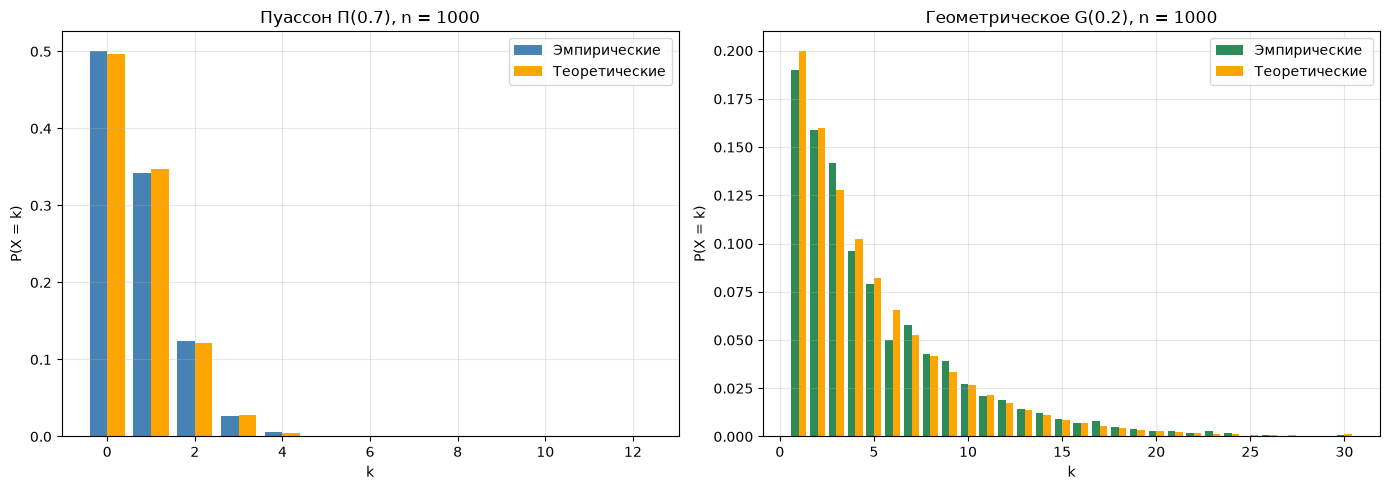

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

vals_p = sorted(probs_p.keys())
emp_p = [np.mean(poisson_seq == k) for k in vals_p]
ax[0].bar(np.array(vals_p) - 0.2, emp_p,
          width=0.4, label='Эмпирические', color='steelblue')
ax[0].bar(np.array(vals_p) + 0.2, [probs_p[k] for k in vals_p],
          width=0.4, label='Теоретические', color='orange')
ax[0].set_title(f'Пуассон П({LAMBDA}), n = {N}')
ax[0].set_xlabel('k'); ax[0].set_ylabel('P(X = k)')
ax[0].legend(); ax[0].grid(alpha=0.3)

vals_g = sorted(probs_g.keys())
emp_g = [np.mean(geo_seq == k) for k in vals_g]
ax[1].bar(np.array(vals_g) - 0.2, emp_g,
          width=0.4, label='Эмпирические', color='seagreen')
ax[1].bar(np.array(vals_g) + 0.2, [probs_g[k] for k in vals_g],
          width=0.4, label='Теоретические', color='orange')
ax[1].set_title(f'Геометрическое G({P_GEO}), n = {N}')
ax[1].set_xlabel('k'); ax[1].set_ylabel('P(X = k)')
ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('lab2_histograms.png', dpi=120, bbox_inches='tight')
plt.show()

In [14]:
print(f"{'Распределение':<20} | {'E[X] теор':>10} | {'E[X] оц':>10} | {'D[X] теор':>10} | {'D[X] оц':>10}")
print("-" * 78)
print(f"{'Пуассон П(0.7)':<20} | {E_POIS:>10.4f} | {mean_p:>10.4f} | {D_POIS:>10.4f} | {var_p:>10.4f}")
print(f"{'Геометрическое':<20} | {E_GEO:>10.4f} | {mean_g:>10.4f} | {D_GEO:>10.4f} | {var_g:>10.4f}")
print()
print(f"{'Выборка':<25} | {'Критерий':<25} | {'χ²':>8} | {'df':>3} | {'crit':>7} | Вердикт")
print("-" * 100)
for seq_name, seq in seqs.items():
    for crit_name, probs in criteria.items():
        r = chi2_test_discrete(seq, probs)
        print(f"{seq_name:<25} | {crit_name:<25} | "
              f"{r['chi2']:>8.4f} | {r['df']:>3} | {r['crit']:>7.4f} | {r['verdict']}")

Распределение        |  E[X] теор |    E[X] оц |  D[X] теор |    D[X] оц
------------------------------------------------------------------------------
Пуассон П(0.7)       |     0.7000 |     0.6950 |     0.7000 |     0.6947
Геометрическое       |     5.0000 |     5.1780 |    20.0000 |    22.1505

Выборка                   | Критерий                  |       χ² |  df |    crit | Вердикт
----------------------------------------------------------------------------------------------------
Пуассон П(0.7)            | Пуассон-критерий          |   0.2531 |   4 |  9.4877 | H0 принимается
Пуассон П(0.7)            | Геометрическое-критерий   | 688.9669 |  23 | 35.1725 | H0 ОТВЕРГАЕТСЯ
Геометрическое G(0.2)     | Пуассон-критерий          | 32612.7866 |   4 |  9.4877 | H0 ОТВЕРГАЕТСЯ
Геометрическое G(0.2)     | Геометрическое-критерий   |  11.5441 |  23 | 35.1725 | H0 принимается
